# Chapter 5 — 사전 학습(Pre-training) : 코드 해설 노트북 (Python 초보용)

> `Chapter_5_Excercise_Pretraining.ipynb` 의 원본 코드 셀은 그대로 두고, 번호가 붙은 셀마다 바로 위에 설명을 넣은 해설판입니다.

## 이 챕터에서 하는 일 (한 문장)

Chapter 4 에서 조립만 해 둔 GPT(가중치가 무작위라 엉터리 글을 쓰던 모델)를 **실제 글로 학습시켜** 그럴듯한 문장을 쓰게 만듭니다.

## 학습이란? — 네 단계의 반복

```
 +---------------------------------------------------+
 |  1. forward    model(input)       ->  logits      |
 |  2. loss       logits vs target   ->  one number  |
 |  3. backward   loss.backward()    ->  gradients   |
 |  4. step       optimizer.step()   ->  update      |
 +---------------------------------------------------+
            repeat for every batch
```

| 단계 | 하는 일 | 시험 공부 비유 |
|---|---|---|
| 1. forward (순전파) | 모델이 예측한다 | 문제를 푼다 |
| 2. loss (손실) | 정답과 얼마나 다른지 **숫자 하나**로 잰다 | 채점한다 |
| 3. backward (역전파) | 각 가중치를 어느 쪽으로 고쳐야 손실이 줄지 계산한다 | 왜 틀렸는지 분석한다 |
| 4. step (갱신) | 가중치를 실제로 조금 고친다 | 다음엔 안 틀리게 고친다 |

## 먼저 알아둘 낱말

| 낱말 | 쉬운 뜻 |
|---|---|
| **손실(loss)** | 틀린 정도. **작을수록 좋다.** |
| **기울기(gradient)** | "이 가중치를 조금 키우면 손실이 얼마나 변하나". 고칠 방향을 알려 주는 화살표 |
| **옵티마이저(optimizer)** | 기울기를 보고 가중치를 실제로 고쳐 주는 도구 |
| **에포크(epoch)** | 학습 데이터 전체를 **한 바퀴** 다 본 것 |
| **검증(validation)** | 학습에 쓰지 않은 데이터로 실력을 확인하는 것 (모의고사) |

## 셀 구성

| 셀 | 내용 |
|---|---|
| 1 | 필요한 도구 불러오기 |
| 2 | `calc_loss_batch` — 배치 하나의 손실 계산 ⭐ |
| 3 | `train_model_simple` — 학습 루프 ⭐ |
| 4 | `generate` — 글 생성 함수 |
| 5 | 보조 함수들 + `main` |
| 6 | 실제로 학습을 실행하고 결과 확인 |

---
## 셀 1 — 도구 불러오기

### 🎯 이 셀이 하는 일
이 노트북에서 쓸 라이브러리와, 앞 챕터에서 만든 것들을 가져옵니다.

### 코드 뜯어보기

| 코드 | 가져오는 것 |
|---|---|
| `import matplotlib.pyplot as plt` | 그래프 그리기 도구. 앞으로 `plt` 라고 부름 |
| `import os` | 파일·폴더가 있는지 확인하는 등 운영체제 기능 |
| `import requests` | 인터넷에서 파일 내려받기 |
| `import torch` | PyTorch |
| `import tiktoken` | 토크나이저 |

```python
from previous_chapters import GPTModel, create_dataloader_v1, generate_text_simple
```
같은 폴더에 있는 `previous_chapters.py` 파일에서 세 가지를 꺼내 옵니다. Chapter 2~4 에서 만든 코드를 파일 하나에 모아 둔 것이라, 매번 다시 적지 않아도 됩니다.

| 이름 | 어느 챕터에서 만들었나 | 역할 |
|---|---|---|
| `GPTModel` | Chapter 4 | GPT 모델 본체 |
| `create_dataloader_v1` | Chapter 2 | 글 → (입력, 정답) 배치 |
| `generate_text_simple` | Chapter 4 | 글 이어 쓰기 |

맨 위 `# Copyright ...` 줄들은 이 코드의 원저자(Sebastian Raschka, 『Build a Large Language Model From Scratch』)와 라이선스를 밝히는 주석입니다.

> `ModuleNotFoundError` 가 나면 노트북을 실행하는 폴더에 `previous_chapters.py` 가 있는지, 해당 패키지가 설치되어 있는지 확인하세요.

In [1]:
# 1
# Copyright (c) Sebastian Raschka under Apache License 2.0 (see LICENSE.txt).
# Source for "Build a Large Language Model From Scratch"
#   - https://www.manning.com/books/build-a-large-language-model-from-scratch
# Code: https://github.com/rasbt/LLMs-from-scratch

import matplotlib.pyplot as plt
import os
import requests
import torch
import tiktoken

from previous_chapters import GPTModel, create_dataloader_v1, generate_text_simple


---
## 셀 2 — `calc_loss_batch` : 손실 계산 (⭐ 중요)

### 🎯 이 셀이 하는 일
배치 하나를 모델에 넣어 예측을 얻고, 정답과 비교해 **"얼마나 틀렸는지"를 숫자 하나(loss)** 로 돌려줍니다. 학습 4단계 중 1, 2단계에 해당합니다.

### 코드 뜯어보기

**① 데이터를 모델과 같은 장치로 옮기기**
```python
input_batch, target_batch = input_batch.to(device), target_batch.to(device)
```
`.to(device)` 는 텐서를 GPU(또는 CPU)로 옮깁니다. 모델이 GPU 에 있으면 데이터도 GPU 에 있어야 계산할 수 있습니다. 한 줄에 두 개를 동시에 대입하는 문법(`a, b = x, y`)을 썼습니다.

**② 순전파**
```python
logits = model(input_batch)
```
모양 : `[배치, 토큰 수, 단어장 크기]`. 모든 자리마다 "다음 토큰 후보 50257개의 점수"가 나옵니다.

**③ 크로스 엔트로피 손실**
```python
loss = torch.nn.functional.cross_entropy(
    logits.flatten(0, 1),
    target_batch.flatten()
)
```

**크로스 엔트로피(cross entropy)란?** "모델이 **정답 토큰에 얼마나 높은 확률**을 줬는가"를 재는 방법입니다.
- 정답에 높은 확률을 줬다 → 손실이 **작다**
- 정답에 낮은 확률을 줬다 → 손실이 **크다**

```
 correct token prob = 0.9   ->  loss ~ 0.1    (good)
 correct token prob = 0.1   ->  loss ~ 2.3
 correct token prob = 0.00002 (= 1/50257, random guess)  ->  loss ~ 10.8
```
그래서 **전혀 학습되지 않은 모델의 손실은 약 10.8** 근처에서 시작합니다. 셀 6의 첫 출력(9.98)이 이 근처인 이유입니다.

이 함수는 내부에서 로짓을 확률로 바꾸는 softmax 까지 **알아서** 해 줍니다. 그래서 모델(`GPTModel`)은 softmax 를 하지 않고 점수(로짓)를 그대로 내보냅니다.

**`flatten` 은 왜 할까?**
`cross_entropy` 는 "**문제 N개, 보기 C개**" 형태, 즉 로짓 `[N, C]` 와 정답 `[N]` 을 받습니다. 그런데 우리 데이터는 배치와 토큰 두 축으로 문제가 나열되어 있으므로 **한 줄로 펴** 줘야 합니다.

```
 logits        [2, 256, 50257]  --flatten(0, 1)-->  [512, 50257]
 target_batch  [2, 256]         --flatten()----->   [512]
```
- `flatten(0, 1)` : 0번 축과 1번 축을 **하나로 합침** (2 × 256 = 512문제)
- `flatten()` : 전부 한 줄로 폄

512개 문제 각각의 손실을 구한 뒤 **평균**을 내서 숫자 하나로 돌려줍니다.

> 💡 `torch.nn.functional` 에는 학습되는 값 없이 계산만 하는 함수들이 모여 있습니다.

In [2]:
# 2
### 중요: lOSS를 계산합니다.
def calc_loss_batch(input_batch, target_batch, model, device):
    """
    하나의 배치(Batch)에 대해 모델의 예측값과 실제값 사이의 오차(Loss)를 계산합니다.
    """
    # 데이터를 GPU(또는 설정된 device)로 이동
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    
    # 1. 모델의 순전파(Forward Pass)
    # logits shape: (batch_size, sequence_length, vocab_size)
    logits = model(input_batch)
    
    # 2. 손실 계산 (CrossEntropyLoss)
    # PyTorch의 CrossEntropyLoss는 입력을 (N, C) 형태로 받기를 원합니다.
    #   - N: 전체 샘플 수 (여기서는 Batch_size * Sequence_length)
    #   - C: 클래스 수 (여기서는 Vocab_size)
    # 따라서 3차원 텐서를 2차원으로 평탄화(flatten) 해야 합니다.
    
    # logits.flatten(0, 1) -> (batch_size * sequence_length, vocab_size)
    # target_batch.flatten() -> (batch_size * sequence_length)
    # region [손실 계산 (CrossEntropyLoss)]
    # TODO: 손실 함수명과 logits/target 평탄화 메서드를 채우세요.
    # 힌트: cross_entropy에 logits.flatten(0, 1)과 target_batch.flatten()을 전달합니다.
    # loss = torch.nn.functional.????(
    loss = torch.nn.functional.cross_entropy(
        # logits.????(0, 1), 
        logits.flatten(0, 1), 
        # target_batch.????()
        target_batch.flatten()
    )
    # endregion
    return loss


---
## 셀 3 — `train_model_simple` : 학습 루프 (⭐ 가장 중요)

### 🎯 이 셀이 하는 일
"배치를 꺼내 → 손실을 구하고 → 가중치를 고치는" 과정을 데이터 전체에 대해, 여러 에포크 동안 반복합니다. **딥러닝 학습 코드의 표준 뼈대**이므로 이 셀의 구조는 통째로 익혀 두면 좋습니다.

### 함수가 받는 인자

| 인자 | 뜻 |
|---|---|
| `model` | 학습시킬 모델 |
| `train_loader` / `val_loader` | 학습용 / 검증용 데이터 로더 |
| `optimizer` | 가중치를 고쳐 주는 도구 |
| `device` | 계산할 장치 (cuda / cpu) |
| `num_epochs` | 데이터를 몇 바퀴 돌지 |
| `eval_freq` | 몇 스텝마다 중간 점검을 할지 |
| `eval_iter` | 중간 점검 때 배치를 몇 개만 볼지 |
| `start_context` | 샘플 문장을 생성할 때 쓸 시작 문구 |
| `tokenizer` | 토크나이저 |

### 코드 뜯어보기

**① 기록장 준비**
```python
train_losses, val_losses, track_tokens_seen = [], [], []
tokens_seen = 0
global_step = -1
```
- 빈 리스트 3개를 한 줄에 만들었습니다. 나중에 그래프를 그리기 위한 기록장입니다.
- `global_step = -1` : 첫 배치를 처리하면 `+= 1` 로 0 이 됩니다. 스텝 번호를 0부터 세기 위한 시작값입니다.

**② 바깥 반복 : 에포크**
```python
for epoch in range(num_epochs):
    model.train()
```
`model.train()` 은 **학습 모드**로 바꿉니다. 드롭아웃이 켜집니다. (중간 점검 때 `eval()` 로 바뀌므로, 에포크마다 다시 켜 줍니다.)

**③ 안쪽 반복 : 배치 — 여기가 학습의 심장**
```python
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()                                         # [Step 1]
        loss = calc_loss_batch(input_batch, target_batch, model, device)  # [Step 2]
        loss.backward()                                               # [Step 3]
        optimizer.step()                                              # [Step 4]
```

| 줄 | 하는 일 | 빠뜨리면? |
|---|---|---|
| `optimizer.zero_grad()` | 지난 배치에서 계산한 기울기를 **0 으로 지움** | PyTorch 는 기울기를 **계속 누적**하므로, 안 지우면 이전 배치 것과 섞여 엉뚱한 방향으로 고침 |
| `loss = calc_loss_batch(...)` | 예측하고 채점 (셀 2) | — |
| `loss.backward()` | **역전파** : 모든 가중치에 대해 "어느 쪽으로 고치면 손실이 줄어드는지"(기울기) 계산 | 기울기가 없어 학습이 안 됨 |
| `optimizer.step()` | 기울기를 보고 가중치를 **실제로 조금 수정** | 계산만 하고 고치지 않아 학습이 안 됨 |

`for input_batch, target_batch in train_loader:` 는 로더가 주는 `(입력, 정답)` 쌍을 두 변수로 바로 풀어 받는 문법입니다.

**④ 진행 상황 세기**
```python
        tokens_seen += input_batch.numel()
        global_step += 1
```
- `.numel()` : 텐서 안의 **원소 개수**(number of elements). 배치 2 × 토큰 256 = 512.
- `a += b` 는 `a = a + b` 의 줄임입니다.

**⑤ 주기적인 중간 점검**
```python
        if global_step % eval_freq == 0:
            train_loss, val_loss = evaluate_model(
                model, train_loader, val_loader, device, eval_iter)
            train_losses.append(train_loss)
            val_losses.append(val_loss)
            track_tokens_seen.append(tokens_seen)
            print(f"Ep {epoch+1} (Step {global_step:06d}): "
                  f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")
```
- `%` 는 **나머지**. `global_step % 5 == 0` 은 "5의 배수 스텝일 때"라는 뜻입니다.
- `evaluate_model` 로 학습/검증 손실을 재고 기록장에 적습니다.
- `{global_step:06d}` : 6자리로 맞추고 빈자리는 0 으로 채움 (5 → `000005`)
- `{train_loss:.3f}` : 소수점 셋째 자리까지
- `epoch+1` : 파이썬은 0부터 세지만 사람은 1부터 세는 게 편해서 1을 더해 표시합니다.

**⑥ 에포크가 끝날 때마다 샘플 글 생성**
```python
    generate_and_print_sample(model, tokenizer, device, start_context)
```
숫자(손실)만으로는 실감이 안 나므로, 모델이 실제로 쓰는 글이 좋아지는지 눈으로 확인합니다. 들여쓰기를 보면 이 줄은 **안쪽 for 문 밖, 바깥 for 문 안**에 있습니다 → 에포크당 한 번 실행.

**⑦ 기록장 돌려주기**
```python
return train_losses, val_losses, track_tokens_seen
```

### ❓ `evaluate_model` 과 `generate_and_print_sample` 은 아직 정의하지 않았는데?
둘 다 **셀 5**에서 정의됩니다. 파이썬은 함수를 **정의할 때**가 아니라 **실제로 부를 때** 그 이름을 찾기 때문에, 이 함수가 실행되는 시점(셀 6)까지만 정의되어 있으면 됩니다. 단, 셀 5를 실행하지 않고 셀 6을 실행하면 `NameError` 가 납니다.

### 구조 한눈에 보기
```
 for epoch:                      <- whole data, num_epochs times
     model.train()
     for batch:                  <- one batch at a time
         zero_grad -> loss -> backward -> step
         every eval_freq steps:  print train / val loss
     print a sample sentence
```

In [3]:
# 3
### 중요: 모델을 학습합니다.
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    """
    [핵심] 모델 훈련을 담당하는 메인 루프입니다.
    """
    # 로그 저장을 위한 리스트들
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen = 0
    global_step = -1

    # Epoch: 전체 데이터셋을 한 번 훑는 단위
    for epoch in range(num_epochs):
        # region [train 모드 설정]
        # TODO: 모델 모드 전환 메서드를 채우세요.
        # 힌트: 학습 루프 시작 전에는 train 모드를 설정해야 합니다.
        # model.????()  # 훈련 시작 전 반드시 train 모드 설정
        model.train()  # 훈련 시작 전 반드시 train 모드 설정
        # endregion
        
        for input_batch, target_batch in train_loader:
            # [Step 1] 이전 배치에서 계산된 기울기 초기화 (필수)
            # region [기울기 초기화]
            # TODO: 기울기 초기화 메서드를 채우세요.
            # 힌트: 배치마다 이전 gradient가 누적되지 않도록 zero_grad()를 먼저 호출합니다.
            # optimizer.????()
            optimizer.zero_grad()
            # endregion
            #              
            # [Step 2] 순전파 및 손실 계산
            # region [손실 계산]
            # TODO: 배치 손실 계산 함수명을 채우세요.
            # 힌트: input_batch, target_batch, model, device를 인자로 받는 헬퍼를 호출하면 됩니다.
            # loss = ????(input_batch, target_batch, model, device)
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            # endregion

            # [Step 3] 역전파 (Backpropagation): 각 파라미터별 기울기(Gradient) 계산
            # region [역전파 수행]
            # TODO: 역전파 메서드를 채우세요.
            # 힌트: loss 텐서에서 backward()를 호출해 gradient를 계산합니다.
            # loss.????() 
            loss.backward() 
            # endregion

            # [Step 4] 가중치 업데이트: 계산된 기울기를 이용해 파라미터 수정
            # region [가중치 업데이트]
            # TODO: 파라미터 업데이트 메서드를 채우세요.
            # 힌트: backward()로 계산된 gradient를 이용해 optimizer.step()으로 가중치를 갱신합니다.
            # optimizer.????() 
            optimizer.step() 
            # endregion
            
            tokens_seen += input_batch.numel() # 처리한 토큰 수 카운트
            global_step += 1

            # 일정 스텝마다 검증(Evaluation) 수행 및 로그 출력
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # 한 에포크가 끝날 때마다 샘플 문장을 생성하여 모델이 똑똑해지고 있는지 확인
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen

---
## 셀 4 — `generate` : 글 생성 함수

### 🎯 이 셀이 하는 일
Chapter 4 의 `generate_text_simple` 과 같은 방식으로 글을 이어 쓰되, **"끝" 표시(EOS 토큰)가 나오면 일찍 멈추는 기능**이 추가된 버전입니다.

> 📝 **독스트링과 실제 코드의 차이** : 설명문에는 `temperature`, `top_k` 가 적혀 있지만, **이 실습 버전의 함수에는 그 두 인자가 없습니다.** 실제 동작은 "항상 점수가 가장 높은 토큰을 고르는" 그리디 방식입니다. (`previous_chapters.py` 에 들어 있는 `generate` 는 두 기능을 모두 갖춘 완전판입니다.)
> - *temperature(온도)* : 높일수록 덜 뻔한(무작위성이 큰) 토큰을 고르게 하는 값
> - *top-k* : 점수 상위 k개 후보 안에서만 고르게 하는 제한

### 코드 뜯어보기

```python
def generate(model, idx, max_new_tokens, context_size, eos_id=None):
```
`eos_id=None` : 기본값이 `None`(없음). 종료 토큰 번호를 넘겨주지 않으면 중간에 멈추지 않습니다.

```python
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]          # 1. 너무 길면 뒤쪽만 사용
        with torch.no_grad():
            logits = model(idx_cond)               # 2. 예측
        logits = logits[:, -1, :]                  # 3. 마지막 자리 점수만
        idx_next = torch.argmax(logits, dim=-1, keepdim=True)   # 가장 높은 점수의 토큰
        if idx_next == eos_id:                     # 4. 끝 표시면 중단
            break
        idx = torch.cat((idx, idx_next), dim=1)    # 5. 뒤에 이어 붙이기
    return idx
```

| 단계 | 설명 |
|---|---|
| 1 | `idx[:, -context_size:]` — 모델이 볼 수 있는 최대 길이만큼 **뒤에서부터** 자름 |
| 2 | `torch.no_grad()` — 학습이 아니므로 기울기 기록을 끔 |
| 3 | `logits[:, -1, :]` — `[b, T, vocab]` → `[b, vocab]`. 마지막 자리가 "다음 토큰" 예측 |
| — | `torch.argmax` — 점수가 가장 큰 **위치 번호** = 토큰 ID |
| 4 | `break` — 반복문을 즉시 빠져나옴. GPT-2 에서 "글 끝" 토큰(endoftext)은 50256 번 |
| 5 | `torch.cat(..., dim=1)` — 토큰 축 방향으로 이어 붙임 |

Chapter 4 버전과 다른 곳은 **4번(종료 조건)뿐**입니다.

`if idx_next == eos_id:` 는 문장을 **한 개씩**(배치 크기 1) 생성할 때를 가정한 코드입니다. 이 노트북에서는 `eos_id` 를 넘기지 않아 항상 `max_new_tokens` 만큼 생성하고, Chapter 7 에서 `eos_id=50256` 을 넘겨 "답변이 끝나면 멈추기"에 활용합니다.

In [4]:
# 4
### 중요: 결과를 생성합니다.
def generate(model, idx, max_new_tokens, context_size, eos_id=None):
    """
    고급 텍스트 생성 함수입니다. (Top-k 샘플링 & Temperature Scaling 포함)
    
    Args:
        idx: 현재 문맥 (Shape: Batch, Time)
        temperature: 0이면 결정적(Greedy), 높을수록 창의적/랜덤
        top_k: 확률 상위 k개만 후보로 남김 (이상한 단어 생성 방지)
    """

    # 지정된 토큰 수만큼 반복 생성
    for _ in range(max_new_tokens):
        
        # 1. 문맥 자르기 (Context Cropping)
        # 모델이 처리할 수 있는 최대 길이(context_size)를 넘지 않도록 뒤쪽만 남김
        idx_cond = idx[:, -context_size:]
        
        # 2. 모델 예측
        # region [모델 예측]
        with torch.no_grad():
            logits = model(idx_cond)
        # endregion

        # 3. 다음 단어 예측을 위해 '마지막 시점'의 로짓만 추출
        # logits shape: (batch, seq_len, vocab_size) -> (batch, vocab_size)
        # region [마지막 시점 로짓 추출]
        # TODO: 마지막 시점 선택 인덱스를 채우세요.
        # 힌트: 다음 토큰 생성은 마지막 위치 logits만 사용합니다.
        # logits = logits[:, ????, :]
        logits = logits[:, -1, :]
        # endregion

        # 가장 높은 확률을 가진 토큰 선택 (Greedy Decoding)
        # region [다음 토큰 선택 (Greedy Decoding)]
        # TODO: 다음 토큰 선택 함수명을 채우세요.
        # 힌트: Greedy decoding에서는 argmax를 사용합니다.
        # idx_next = torch.????(logits, dim=-1, keepdim=True)
        idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        # endregion

        # 4. 종료 조건 확인 (EOS 토큰이 나오면 중단)
        if idx_next == eos_id:
            break

        # 5. 생성된 토큰 이어붙이기
        # 기존 문장(idx) 뒤에 새로 뽑은 토큰(idx_next)을 붙여 다음 스텝의 입력으로 씀
        # region [생성된 토큰 이어붙이기]
        # TODO: concat 대상 변수를 채우세요.
        # 힌트: 방금 고른 idx_next를 기존 idx 뒤에 붙입니다.
        # idx = torch.cat((idx, ????), dim=1)
        idx = torch.cat((idx, idx_next), dim=1)
        # endregion
        
    return idx


---
## 셀 5 — 보조 함수들과 `main`

### 🎯 이 셀이 하는 일
학습에 필요한 **도우미 함수 6개**와, 준비부터 학습까지 전 과정을 순서대로 실행하는 **`main` 함수**를 정의합니다. 셀이 길지만 함수 하나하나는 단순합니다.

| 함수 | 한 줄 역할 |
|---|---|
| `text_to_token_ids` | 글 → 토큰 ID 텐서 |
| `token_ids_to_text` | 토큰 ID 텐서 → 글 |
| `calc_loss_loader` | 로더 전체(또는 일부)의 **평균 손실** |
| `evaluate_model` | 학습/검증 손실을 재는 중간 점검 |
| `generate_and_print_sample` | 샘플 문장을 생성해 출력 |
| `plot_losses` | 손실 그래프 그리기 |
| `main` | 데이터 준비 → 모델 생성 → 학습 실행 |

---
### ① `text_to_token_ids` / `token_ids_to_text`
```python
encoded = tokenizer.encode(text)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
```
```python
flat = token_ids.squeeze(0)
return tokenizer.decode(flat.tolist())
```
- `unsqueeze(0)` : 맨 앞에 크기 1짜리 축 추가. `[12, 34, 56]` → `[[12, 34, 56]]` (모양 `[3]` → `[1, 3]`). 모델이 `[배치, 토큰]` 형태를 원하기 때문입니다.
- `squeeze(0)` : 그 반대. 맨 앞의 크기 1짜리 축 제거.
- `.tolist()` : 텐서 → 파이썬 리스트

서로 **정반대** 일을 하는 한 쌍입니다.

---
### ② `calc_loss_loader` — 평균 손실
```python
total_loss = 0.
if len(data_loader) == 0:
    return float("nan")
elif num_batches is None:
    num_batches = len(data_loader)
else:
    num_batches = min(num_batches, len(data_loader))
```
- `0.` 은 `0.0`(실수)입니다.
- 로더가 비어 있으면 `nan`(Not a Number, "계산 불가" 표시)을 돌려줍니다.
- `num_batches` 를 안 주면 전체를, 주면 **그 개수만큼만** 봅니다. `min(a, b)` 는 둘 중 작은 값 → 로더에 있는 배치 수보다 많이 요구하는 실수를 막습니다.

```python
for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
        loss = calc_loss_batch(input_batch, target_batch, model, device)
        total_loss += loss.item()
    else:
        break
return total_loss / num_batches
```
- `enumerate(...)` : 번호 `i` 와 내용물을 함께 꺼냅니다. 내용물이 쌍이라 괄호 `(input_batch, target_batch)` 로 한 번 더 풀었습니다.
- `loss.item()` : 값 하나짜리 텐서에서 **파이썬 숫자만** 꺼냅니다.
- 합계 ÷ 개수 = 평균.

---
### ③ `evaluate_model` — 중간 점검
```python
model.eval()
with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
model.train()
return train_loss, val_loss
```
**샌드위치 구조**를 기억하세요.
```
 model.eval()        <- turn off dropout
   torch.no_grad()   <- no gradient bookkeeping
     ... measure ...
 model.train()       <- back to training mode
```
시험을 볼 때는 (1) 무작위 요소를 끄고 (2) 기록도 끄고, 끝나면 (3) 다시 학습 모드로 되돌립니다.

---
### ④ `generate_and_print_sample` — 샘플 문장
```python
model.eval()
context_size = model.pos_emb.weight.shape[0]
encoded = text_to_token_ids(start_context, tokenizer).to(device)
with torch.no_grad():
    token_ids = generate_text_simple(model=model, idx=encoded,
                                     max_new_tokens=50, context_size=context_size)
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
model.train()
```
- `model.pos_emb.weight.shape[0]` : 위치 임베딩 표의 **행 수** = 모델이 볼 수 있는 최대 길이. 설정값을 따로 넘겨받지 않고 모델에서 직접 알아내는 요령입니다.
- `.replace("\n", " ")` : 줄바꿈을 공백으로 바꿔 한 줄로 출력합니다.
- 여기도 `eval()` … `train()` 샌드위치입니다.

---
### ⑤ `plot_losses` — 손실 그래프
```python
fig, ax1 = plt.subplots()
ax1.plot(epochs_seen, train_losses, label="Training loss")
ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend(loc="upper right")

ax2 = ax1.twiny()
ax2.plot(tokens_seen, train_losses, alpha=0)
ax2.set_xlabel("Tokens seen")
```
- `ax1.plot(x, y, label=...)` : 선 그래프. `linestyle="-."` 는 점선, `legend` 는 범례.
- `ax1.twiny()` : **y축을 공유하는 두 번째 x축**을 위쪽에 만듭니다. 아래 x축은 에포크, 위 x축은 "본 토큰 수"를 표시하려는 것입니다.
- `alpha=0` : 완전 투명. 선은 안 보이게 하고 **축 눈금만** 생기게 하는 요령입니다.

---
### ⑥ `main(gpt_config, settings)` — 전 과정 실행

**1. 데이터 준비**
```python
if not os.path.exists(file_path):
    response = requests.get(url, timeout=30)
    ...
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()
```
파일이 없으면 내려받아 저장하고, 있으면 읽기만 합니다 (Chapter 2 와 같은 소설 `the-verdict.txt`).

**2. 모델과 옵티마이저**
```python
model = GPTModel(gpt_config)
model.to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=settings["learning_rate"], weight_decay=settings["weight_decay"]
)
```
- `model.parameters()` : 모델 안의 **학습 가능한 모든 숫자**를 옵티마이저에게 넘깁니다. "이것들을 네가 고쳐라"는 뜻입니다.
- `AdamW` : 가장 널리 쓰이는 옵티마이저 중 하나입니다.
- `lr` (learning rate, **학습률**) : 한 번에 얼마나 크게 고칠지. 너무 크면 널뛰고, 너무 작으면 느립니다.
- `weight_decay` : 가중치가 지나치게 커지지 않도록 살짝 눌러 주는 정도(과적합 완화).

**3. 데이터 나누기와 로더 만들기**
```python
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
```
글의 앞 90% 는 학습용, 뒤 10% 는 검증용으로 씁니다. `int()` 는 소수점을 버려 정수로 만듭니다(슬라이싱 번호는 정수여야 함).

```python
train_loader = create_dataloader_v1(text_data[:split_idx], ..., drop_last=True,  shuffle=True)
val_loader   = create_dataloader_v1(text_data[split_idx:], ..., drop_last=False, shuffle=False)
```

| | 학습용 | 검증용 | 이유 |
|---|---|---|---|
| `shuffle` | True | False | 학습은 순서를 섞어야 고르게 배우고, 평가는 매번 같은 조건이어야 비교가 됨 |
| `drop_last` | True | False | 학습은 크기가 모자란 자투리 배치를 버리고, 평가는 데이터를 하나도 버리지 않음 |

`stride = max_length = context_length` 이므로 조각들이 **겹치지 않게** 잘립니다.

**4. 학습 시작**
```python
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=settings["num_epochs"], eval_freq=5, eval_iter=1,
    start_context="Every effort moves you", tokenizer=tokenizer
)
return train_losses, val_losses, tokens_seen, model
```
셀 3의 학습 루프를 부릅니다. 5스텝마다 점검하고(`eval_freq=5`), 점검 때는 배치 1개만 봅니다(`eval_iter=1`).

> 이 셀은 정의만 하므로 출력이 없습니다.

In [5]:
# 5
def text_to_token_ids(text, tokenizer):
    """
    사람이 읽는 텍스트 문자열을 모델이 이해하는 토큰 ID 텐서로 변환합니다.
    """
    encoded = tokenizer.encode(text)
    
    # 모델은 입력으로 (Batch_Size, Sequence_Length)의 2차원 텐서를 요구합니다.
    # 하지만 여기서는 문장 1개이므로 Batch_Size가 없습니다.
    # 따라서 .unsqueeze(0)를 사용하여 가짜 배치 차원을 추가합니다.
    # 예: [12, 34, 56] -> [[12, 34, 56]] (Shape: [1, seq_len])
    # TODO: 배치 차원 추가 메서드를 채우세요.
    # 힌트: 단일 시퀀스를 모델 입력 형태로 만들기 위해 unsqueeze(0)를 사용합니다.
    # encoded_tensor = torch.tensor(encoded).????(0) 
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) 
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    """
    모델이 뱉어낸 토큰 ID 텐서를 사람이 읽을 수 있는 텍스트로 변환합니다.
    """
    # 디코딩을 위해 불필요한 배치 차원을 제거합니다.
    # 예: [[12, 34, 56]] -> [12, 34, 56]
    # TODO: 배치 차원 제거 메서드를 채우세요.
    # 힌트: 디코딩 전에는 squeeze(0)로 앞쪽 차원을 제거합니다.
    # flat = token_ids.????(0) 
    flat = token_ids.squeeze(0) 
    return tokenizer.decode(flat.tolist())


def calc_loss_loader(data_loader, model, device, num_batches=None):
    """
    데이터 로더 전체(또는 일부)를 돌면서 평균 손실을 계산합니다.
    훈련에는 관여하지 않고, 오직 '평가(Evaluation)' 목적으로만 쓰입니다.
    """
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # 평가 시간을 단축하기 위해 전체 데이터를 다 보지 않고 일부만 볼 수 있게 설정
        num_batches = min(num_batches, len(data_loader))
        
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item() # 텐서에서 실수값(float)만 추출하여 누적
        else:
            break
    return total_loss / num_batches


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    """
    현재 모델의 성능을 훈련 세트와 검증 세트 각각에 대해 평가합니다.
    """
    model.eval() # [중요] 평가 모드 전환: Dropout이나 BatchNorm 등의 동작이 변경됨
    
    with torch.no_grad(): # [중요] 기울기(Gradient) 계산 끔 -> 메모리 절약 및 속도 향상
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
        
    model.train() # 평가가 끝나면 다시 훈련 모드로 복귀해야 함
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    """
    훈련 중간중간 모델이 문장을 어떻게 생성하는지 눈으로 확인하기 위한 함수입니다.
    """
    model.eval() # 평가 모드
    context_size = model.pos_emb.weight.shape[0] # 모델이 처리 가능한 최대 길이
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
        decoded_text = token_ids_to_text(token_ids, tokenizer)
        
        # 출력이 너무 길어지면 보기 힘드므로 줄바꿈을 공백으로 변경
        print(decoded_text.replace("\n", " "))  
    
    model.train() # 훈련 모드 복귀



def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    """
    훈련 진행 상황(Loss 변화)을 시각화하는 함수입니다.
    X축을 'Epoch'와 '처리한 토큰 수' 두 가지 기준으로 보여줍니다.
    """
    fig, ax1 = plt.subplots()

    # 기본 X축: Epoch 기준
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")

    # 보조 X축 (상단): 처리한 토큰 수(Tokens seen) 기준
    ax2 = ax1.twiny() 
    ax2.plot(tokens_seen, train_losses, alpha=0) # 투명한 그래프로 축만 생성
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout() 
    # plt.show() # 주피터 노트북 환경이면 주석 해제


def main(gpt_config, settings):
    # 랜덤 시드 고정 (실험 재현성을 위해)
    torch.manual_seed(123)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    ##############################
    # 1. 데이터 준비
    ##############################
    file_path = "data/the-verdict.txt"
    url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

    if not os.path.exists(file_path):
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        text_data = response.text
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    ##############################
    # 2. 모델 및 옵티마이저 초기화
    ##############################
    model = GPTModel(gpt_config)
    model.to(device) # 모델을 GPU 메모리로 올림
    
    # AdamW: 가중치 감쇠(Weight Decay)가 적용된 Adam 옵티마이저
    # Weight Decay는 모델이 너무 복잡해지지 않도록 규제(Regularization)하는 역할
    # TODO: AdamW에 넘길 파라미터 이터레이터와 학습률 키워드를 채우세요.
    # 힌트: 첫 번째 인자는 model.parameters(), 학습률은 lr=settings["learning_rate"] 형태입니다.
    optimizer = torch.optim.AdamW(
        # model.????(), ????=settings["learning_rate"], weight_decay=settings["weight_decay"]
        model.parameters(), lr=settings["learning_rate"], weight_decay=settings["weight_decay"]
    )

    ##############################
    # 3. 데이터 로더 구축
    ##############################
    # 전체 텍스트를 9:1 비율로 훈련용과 검증용으로 나눔
    train_ratio = 0.90
    split_idx = int(train_ratio * len(text_data))

    # 훈련 데이터 로더: 순서를 섞음(Shuffle=True)
    train_loader = create_dataloader_v1(
        text_data[:split_idx],
        batch_size=settings["batch_size"],
        max_length=gpt_config["context_length"],
        stride=gpt_config["context_length"],
        drop_last=True,
        shuffle=True,
        num_workers=0
    )

    # 검증 데이터 로더: 순서를 섞지 않음(Shuffle=False) -> 평가는 일관되게
    val_loader = create_dataloader_v1(
        text_data[split_idx:],
        batch_size=settings["batch_size"],
        max_length=gpt_config["context_length"],
        stride=gpt_config["context_length"],
        drop_last=False,
        shuffle=False,
        num_workers=0
    )

    ##############################
    # 4. 훈련 시작
    ##############################
    tokenizer = tiktoken.get_encoding("gpt2") # BPE 토크나이저

    train_losses, val_losses, tokens_seen = train_model_simple(
        model, train_loader, val_loader, optimizer, device,
        num_epochs=settings["num_epochs"], eval_freq=5, eval_iter=1,
        start_context="Every effort moves you", tokenizer=tokenizer
    )

    return train_losses, val_losses, tokens_seen, model


---
## 셀 6 — 실제 학습 실행과 결과 확인

### 🎯 이 셀이 하는 일
설정값을 정하고 → `main` 으로 학습을 실행하고 → 손실 그래프를 저장하고 → 모델을 파일로 저장했다가 다시 불러와 → 글을 생성해 봅니다.

### 코드 뜯어보기

**① 설정**
```python
GPT_CONFIG_124M = { ..., "context_length": 256, ... }
OTHER_SETTINGS = {
    "learning_rate": 5e-4,   # 0.0005
    "num_epochs": 10,
    "batch_size": 2,
    "weight_decay": 0.1
}
```
- `context_length` 를 원래의 1024 대신 **256** 으로 줄였습니다. 데이터가 아주 작고(소설 한 편) 실습을 빨리 끝내기 위해서입니다.
- `5e-4` 는 5 × 10⁻⁴ = 0.0005 입니다.
- 이런 "사람이 정해 주는 값"들을 **하이퍼파라미터**라고 합니다.

**② 학습 실행**
```python
train_losses, val_losses, tokens_seen, model = main(GPT_CONFIG_124M, OTHER_SETTINGS)
```
`main` 이 돌려준 4개 값을 네 변수에 나눠 받습니다. 이 한 줄이 실행되는 동안 아래 로그가 출력됩니다.

**③ 그래프 저장**
```python
epochs_tensor = torch.linspace(0, OTHER_SETTINGS["num_epochs"], len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)
plt.savefig("output/loss.pdf")
```
`torch.linspace(0, 10, n)` : 0부터 10까지를 **같은 간격으로 n등분**한 숫자들. 기록한 손실 개수에 맞춰 x축(에포크) 좌표를 만든 것입니다. `output` 폴더가 미리 있어야 저장됩니다.

**④ 모델 저장 → 다시 불러오기**
```python
torch.save(model.state_dict(), "output/model.pth")

model = GPTModel(GPT_CONFIG_124M)                                         # 1. 빈 모델
model.load_state_dict(torch.load("output/model.pth", weights_only=True))  # 2. 가중치 채우기
model.to(device)                                                          # 3. GPU 로 이동
```
- `model.state_dict()` : 모델의 모든 가중치를 "이름 → 숫자 표" 딕셔너리로 꺼낸 것. 이것만 저장하면 됩니다.
- 불러올 때는 **같은 설정으로 빈 모델을 먼저 만들고** 거기에 숫자를 채웁니다 (집을 다시 짓고 가구를 들여놓는 순서).
- `weights_only=True` : 파일에서 숫자(가중치)만 읽도록 하는 안전 옵션.
- 새로 만든 모델은 CPU 에 있으므로 `.to(device)` 로 GPU 에 옮겨야 GPU 에 있는 입력과 계산할 수 있습니다.

**⑤ 생성 테스트**
```python
token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("출력 텍스트:\n", token_ids_to_text(token_ids, tokenizer))
```
> 📝 바로 위 주석에 "Temperature=1.4 로 설정하여…"라고 적혀 있지만, 이 호출에는 temperature 를 넘기지 않으며 셀 4의 `generate` 에도 그 기능이 없습니다. 실제로는 **그리디(가장 높은 점수 선택)** 로 생성됩니다.

### 실행 결과 읽기

```
Ep 1 (Step 000000): Train loss 9.982, Val loss 9.841
Every effort moves you,,,,,,,,,,,,.
...
Ep 5 (Step 000040): Train loss 4.613, Val loss 6.390
Every effort moves you, with a, and, and, and, in a little, ...
...
Ep 10 (Step 000085): Train loss 0.633, Val loss 6.431
Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!" ...
```

**1) 글이 점점 사람 말처럼 변합니다**

| 에포크 | 생성된 글 | 상태 |
|---|---|---|
| 1 | `,,,,,,,,,,,,.` | 가장 흔한 기호만 반복 |
| 3 | `, and, and, and, ...` | 흔한 단어를 배움 |
| 5 | `with a, and, in a little, ...` | 짧은 구절이 생김 |
| 10 | `"Yes--quite insensible to the irony. ..."` | 문장다운 문장 |

Chapter 4 의 엉터리 글과 비교하면, **구조는 그대로인데 가중치만 학습으로 바뀌어** 이런 차이가 생긴 것입니다.

**2) 두 손실이 다르게 움직입니다 — 과적합(overfitting)**

```
 Train loss :  9.98 -> 5.2 -> 2.4 -> 0.63     keeps falling
 Val   loss :  9.84 -> 6.5 -> 6.1 -> 6.43     stops around 6.2 and creeps up
```
- 학습 손실은 계속 줄지만 검증 손실은 6 근처에서 멈췄다가 오히려 조금 올라갑니다.
- 이는 모델이 글 쓰는 법을 **이해**했다기보다 학습용 소설을 **통째로 외우고** 있다는 신호입니다. 실제로 10 에포크의 문장은 소설 원문과 거의 같습니다.
- 원인은 데이터가 너무 적기 때문입니다(토큰 약 5천 개 vs. 가중치 1억 개 이상). 실제 GPT 는 이보다 비교할 수 없이 많은 글로 학습합니다. 그래서 다음 챕터부터는 **OpenAI 가 미리 학습해 둔 GPT-2 가중치**를 불러와서 사용합니다.

**3) 마지막 출력**
```
출력 텍스트:
 Every effort moves you?"

"Yes--quite insensible to the fact with a laugh
```
저장했다가 다시 불러온 모델도 학습된 대로 글을 씁니다 → 저장/불러오기가 제대로 됐다는 확인입니다.

Ep 1 (Step 000000): Train loss 9.982, Val loss 9.841
Ep 1 (Step 000005): Train loss 7.849, Val loss 8.041
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.274, Val loss 6.803
Ep 2 (Step 000015): Train loss 5.820, Val loss 6.572
Every effort moves you, the,.                                              
Ep 3 (Step 000020): Train loss 5.920, Val loss 6.551
Ep 3 (Step 000025): Train loss 5.614, Val loss 6.887
Every effort moves you, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and
Ep 4 (Step 000030): Train loss 5.208, Val loss 6.551
Ep 4 (Step 000035): Train loss 5.352, Val loss 6.478
Every effort moves you, and I had the a, and, and, and a.              "I, and I had a, and he had a, and he had the of the of the of
Ep 5 (Step 000040): Train loss 4.613, Val loss 6.390
Every effort moves you, with a, and, and, and, in a little, in a of the picture to have, in 

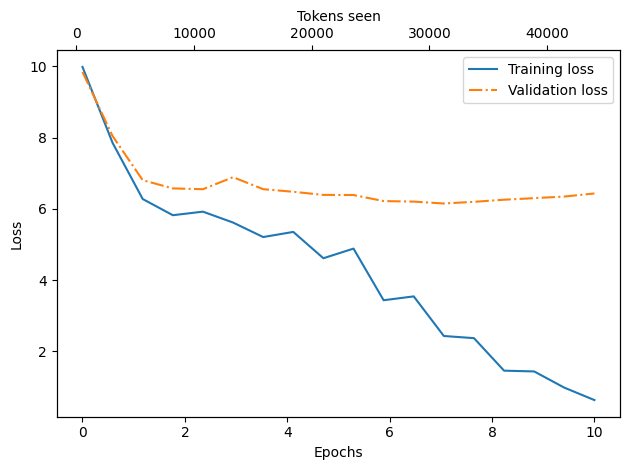

In [6]:
# 6

# GPT-2 Small (124M) 모델 설정
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # 어휘 크기
    "context_length": 256,  # 훈련 속도를 위해 원본(1024)보다 줄임
    "emb_dim": 768,         # 임베딩 벡터 차원
    "n_heads": 12,          # 어텐션 헤드 개수
    "n_layers": 12,         # 레이어 깊이
    "drop_rate": 0.1,       # 과적합 방지 드롭아웃
    "qkv_bias": False       
}

# 학습 하이퍼파라미터
OTHER_SETTINGS = {
    "learning_rate": 5e-4, 
    "num_epochs": 10,       
    "batch_size": 2,        
    "weight_decay": 0.1     
}

###########################
# 메인 실행: 훈련
###########################
train_losses, val_losses, tokens_seen, model = main(GPT_CONFIG_124M, OTHER_SETTINGS)

###########################
# 훈련 결과 시각화 및 저장
###########################

# 에포크 축 생성 (0부터 num_epochs까지)
epochs_tensor = torch.linspace(0, OTHER_SETTINGS["num_epochs"], len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)
plt.savefig("output/loss.pdf")

# 모델 저장 및 로드 테스트
torch.save(model.state_dict(), "output/model.pth")

# 디바이스 설정 (모델 로드 전에 정의 필요)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 모델 다시 불러오기 테스트
model = GPTModel(GPT_CONFIG_124M) # 1. 빈 모델 생성 (현재 CPU에 있음)
model.load_state_dict(torch.load("output/model.pth", weights_only=True)) # 2. 가중치 로드
model.to(device) # <--- [핵심 수정] 3. 모델을 GPU로 이동시켜야 함

torch.manual_seed(123)
###########################
# 생성 테스트 (Inference)
###########################
tokenizer = tiktoken.get_encoding("gpt2")

# 훈련된 모델로 텍스트 생성 시도
# Temperature=1.4로 설정하여 다소 창의적/다양한 문장 생성 유도
token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("출력 텍스트:\n", token_ids_to_text(token_ids, tokenizer))

---
## 📌 Chapter 5 정리

**학습 루프의 뼈대 (통째로 기억하기)**
```python
for epoch in range(num_epochs):
    model.train()
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()      # 1. 지난 기울기 지우기
        loss = calc_loss_batch(...)  # 2. 예측하고 채점
        loss.backward()            # 3. 고칠 방향 계산
        optimizer.step()           # 4. 가중치 수정
```

**꼭 기억할 4가지**
1. **손실(loss)** = 틀린 정도. 크로스 엔트로피는 "정답 토큰에 준 확률이 낮을수록" 커진다.
2. `zero_grad → backward → step` 세 줄은 항상 한 묶음.
3. 평가할 때는 `model.eval()` + `torch.no_grad()`, 끝나면 `model.train()`.
4. 학습 손실만 줄고 검증 손실이 안 줄면 **과적합**(외우기)이다.